# RappiPlus Business Performance Analysis

El objetivo de este proyecto es evaluar el desempeño del servicio **RappiPlus** para apoyar decisiones de negocio basadas en datos.

Se trabajan con múltiples datasets del negocio:

- **rappiplus_orders_raw.csv** → información de pedidos, precios, descuentos y revenue  
- **rappiplus_catalog.csv** → costos de productos, categorías y proveedores  
- **rappiplus_marketing_spend.csv** → inversión en marketing por canal y país  
- **events / users / user_activity (SQL)** → comportamiento del usuario dentro de la plataforma  
- **experiment_checkout_ui.csv** → resultados de un experimento A/B en el checkout  

El análisis sigue una lógica clara y progresiva:

1. 🔍 Evaluar si podemos confiar en los datos (calidad de datos en Python) 

2. 💰 Analizar si el negocio es rentable (revenue, costos y profit)  

3. 🛒 Entender dónde se pierden los usuarios (funnel de conversión)  

4. 🔁 Evaluar si los usuarios regresan (retención por cohortes)  

5. 🧪 Validar si los cambios generan impacto (test estadístico)  

6. 📊 Comunicar los resultados (dashboard en BI)  

A lo largo del proyecto, se transforman datos en insights para responder preguntas clave del negocio y proponer recomendaciones accionables.

---

##  Cargar y validar la calidad de los datos

### Carga de datos y vista rápida

In [1]:
# Importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Cargar archivos
orders = pd.read_csv("https://practicum-content.s3.amazonaws.com/datasets/rappiplus_orders_raw.csv")
catalog = pd.read_csv("https://practicum-content.s3.amazonaws.com/datasets/rappiplus_catalog.csv")
marketing = pd.read_csv("https://practicum-content.s3.amazonaws.com/datasets/rappiplus_marketing_spend.csv")

In [3]:
# Vista previa de de orders
orders.head()

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28


In [4]:
# Vista previa de catalog
catalog.head()

,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC
3,Blender-XL-Red,Hogar,176.64,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.60,"Rivera, Carr and Finley"


In [5]:
# Vista previa de marketing
marketing.head()

,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01
3,2025-01-01,Colombia,organic_Colombia,organic,2597.21
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,1771.40


### Revisión y calidad de datos

Se revisan los 3 datasets
- Validación y conversión de fechas al formato correcto  
- Revisión de variables numéricas (sin negativos o ceros inválidos)
- Verificación de consistencia de montos  
- Eliminación de duplicados  
- Revisión de variables categóricas 

#### Revisión de **orders**:

In [6]:
# Validación general de datos y formatos
print(f"Información general:")
orders.info()

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pedido           25100 non-null  object 
 1   id_usuario          25100 non-null  object 
 2   fecha_hora_pedido   25100 non-null  object 
 3   pais                24800 non-null  object 
 4   dispositivo         25080 non-null  object 
 5   fuente_referencia   25070 non-null  object 
 6   nombre_producto     25070 non-null  object 
 7   categoria_producto  25020 non-null  object 
 8   cantidad            25050 non-null  float64
 9   precio_unitario     25050 non-null  float64
 10  monto_descuento     25050 non-null  float64
 11  monto_total         25100 non-null  float64
dtypes: float64(4), object(8)
memory usage: 2.3+ MB


In [7]:
# Conteo de valores nulos por columna
print(f"Valores nulos: \n", orders.isna().sum())
filas_con_nulos = orders.isna().any(axis=1).sum()
print(f"\nRegistros con al menos un valor nulo:", filas_con_nulos)

Valores nulos: 
 id_pedido               0
id_usuario              0
fecha_hora_pedido       0
pais                  300
dispositivo            20
fuente_referencia      30
nombre_producto        30
categoria_producto     80
cantidad               50
precio_unitario        50
monto_descuento        50
monto_total             0
dtype: int64

Registros con al menos un valor nulo: 400


In [8]:
# Conteo de duplicados por la clave primaria única "id_pedido"
print(f"Duplicados en id_pedido: ", orders["id_pedido"].duplicated().sum())
orders[orders.duplicated(subset="id_pedido", keep=False)].sort_values("id_pedido").head(6)

Duplicados en id_pedido:  100


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
25023,order_10082,user_690,2025-02-17,Argentina,desktop,social,Sneakers-Urban-42,Moda,2.0,221.34,0.0,442.67
10082,order_10082,user_690,2025-02-17,Argentina,desktop,social,Sneakers-Urban-42,Moda,2.0,221.34,0.0,442.67
25037,order_10709,user_6783,2025-02-16,Colombia,mobile,organic,Jacket-Winter-M,Moda,1.0,170.10,10.0,160.10
10709,order_10709,user_6783,2025-02-16,Colombia,mobile,organic,Jacket-Winter-M,Moda,1.0,170.10,10.0,160.10
25065,order_10829,user_7697,2025-01-23,Argentina,mobile,social,Phone-Pro-128GB,Electronica,2.0,115.54,0.0,231.08
10829,order_10829,user_7697,2025-01-23,Argentina,mobile,social,Phone-Pro-128GB,Electronica,2.0,115.54,0.0,231.08


Descripción estadística de variables numérica: 
           cantidad  precio_unitario  monto_descuento   monto_total
count  25050.000000     25050.000000     25050.000000  2.510000e+04
mean       7.092735       259.305549         4.500798  2.072680e+03
std      296.277003       138.726461         5.223010  9.894995e+04
min       -2.000000        20.030000         0.000000 -4.926500e+02
25%        1.000000       138.377500         0.000000  1.805075e+02
50%        2.000000       258.715000         0.000000  3.417500e+02
75%        2.000000       380.332500        10.000000  5.185800e+02
max    20000.000000       499.960000        15.000000  8.840200e+06

Casos con cantidades o montos totales negativos:


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
266,order_266,user_7011,2025-03-13,NaN,desktop,paid_search,Phone-Pro-128GB,Electronica,-2.0,101.31,10.0,-192.62
267,order_267,user_1087,2025-05-07,NaN,desktop,social,Phone-Pro-128GB,Electronica,-1.0,43.50,5.0,-38.50
268,order_268,user_84,2025-02-19,NaN,desktop,organic,Phone-Pro-128GB,Electronica,-1.0,497.65,5.0,-492.65
269,order_269,user_3323,2025-05-25,NaN,desktop,paid_search,Phone-Pro-128GB,Electronica,-1.0,423.53,0.0,-423.53



Boxplot de variables numéricas: 


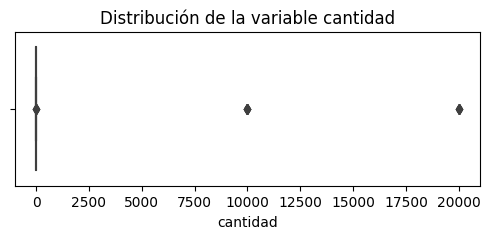

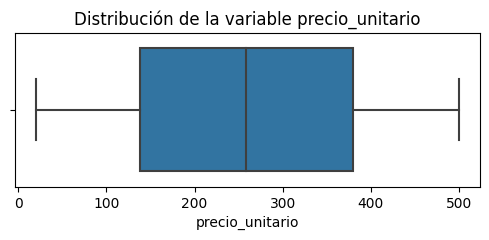

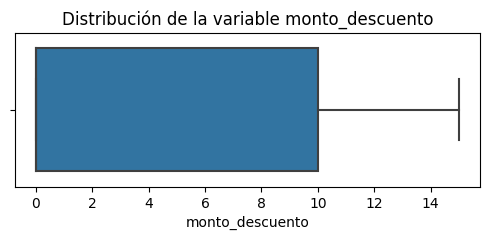

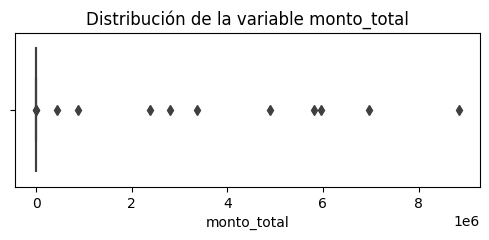

In [9]:
# Variables numéricas para análisis

orders_variables_numericas = ["cantidad", "precio_unitario", "monto_descuento", "monto_total"]

# Descripción estadística de variables numéricas
print(f"Descripción estadística de variables numérica: ")
print(orders[orders_variables_numericas].describe())

# Casos en los que cantidad y monto_total son negativos
print(f"\nCasos con cantidades o montos totales negativos:")
registros_negativos = orders[(orders["cantidad"] < 0) | (orders["monto_total"] < 0)]
display(registros_negativos)

# Boxplot de variables numéricas
print(f"\nBoxplot de variables numéricas: ")
for col in orders_variables_numericas:
    plt.figure(figsize = (6, 2))
    sns.boxplot(x=orders[col])
    plt.title(f'Distribución de la variable {col}')
    plt.show()

In [10]:
# Variables categóricas para análisis

orders_variables_categoricas = ["pais", "dispositivo", "fuente_referencia", "nombre_producto", "categoria_producto"]

# Descripción destadística y conteos de variables categóricas
for col in orders_variables_categoricas:
    print(f"\nDescripción estadística de {col}:")
    print(orders[col].describe())
    tabla_frecuencias = pd.DataFrame({
        "Frecuencia absoluta": orders[col].value_counts(),
        "Frecuencia relativa (%)": orders[col].value_counts(normalize=True).round(4)*100
    })
    print(f"\nTabla de frecuencias {col}:")
    display(tabla_frecuencias)


Descripción estadística de pais:
count        24800
unique           6
top       Colombia
freq          7520
Name: pais, dtype: object

Tabla de frecuencias pais:


,Frecuencia absoluta,Frecuencia relativa (%)
Colombia,7520,30.32
Mexico,7502,30.25
Argentina,7291,29.40
mexico,865,3.49
colombia,823,3.32
argentina,799,3.22



Descripción estadística de dispositivo:
count       25080
unique          2
top       desktop
freq        12759
Name: dispositivo, dtype: object

Tabla de frecuencias dispositivo:


,Frecuencia absoluta,Frecuencia relativa (%)
desktop,12759,50.87
mobile,12321,49.13



Descripción estadística de fuente_referencia:
count      25070
unique         3
top       social
freq        8428
Name: fuente_referencia, dtype: object

Tabla de frecuencias fuente_referencia:


,Frecuencia absoluta,Frecuencia relativa (%)
social,8428,33.62
organic,8329,33.22
paid_search,8313,33.16



Descripción estadística de nombre_producto:
count                25070
unique                   7
top       Vacuum-Pro-Black
freq                  4199
Name: nombre_producto, dtype: object

Tabla de frecuencias nombre_producto:


,Frecuencia absoluta,Frecuencia relativa (%)
Vacuum-Pro-Black,4199,16.75
Blender-XL-Red,4195,16.73
Jacket-Winter-M,4192,16.72
Sneakers-Urban-42,4160,16.59
Laptop-Gaming-16GB,2794,11.14
Tablet-Standard-64GB,2780,11.09
Phone-Pro-128GB,2750,10.97



Descripción estadística de categoria_producto:
count     25020
unique        3
top       Hogar
freq       8385
Name: categoria_producto, dtype: object

Tabla de frecuencias categoria_producto:


,Frecuencia absoluta,Frecuencia relativa (%)
Hogar,8385,33.51
Moda,8323,33.27
Electronica,8312,33.22


**Diagnóstico y tratamiento**:

* La variable `fecha_hora_pedido` está en formato `object`.
   - *Tratamiento*: se convierte a formato fecha.
* Hay 300 registros con `pais` nulo (1.20% del dataset)
* Hay 20 registros con `dispositivo`nulo (0.08% del dataset).
* Hay 30 registros con `fuente_referencia` o `nombre_producto` nulo (0.12% del dataset).
* Hay 80 registros con `categoria_producto` nulo (0.32% del dataset).
* Hay 50 registros con `cantidad`, `precio_unitario` y `monto_descuento` nulo (0.2% del dataset).
   - *Tratamiento*: De los 610 valores nulos en total, estos se presentan en 400 registros, aproximadamente el **1.6% del dataset**. Con la finalidad de evitar inconsistencias y permitir filtrado y segmentaciones con base a variables categóricas, y análisis numéricos, se eliminarán estos registros.
* La variable `id_pedido` tiene 100 duplicados. 
   - *Tratamiento*: al ser el identificador único, se eliminan los duplicados del dataset.
* Las variables numéricas `cantidad` y `monto_total` presentan valores negativos que no son posibles. 4 casos en total.
   - *Tratamiento*: se eliminan del dataset.
* Se identificaron 10 transacciones del producto `Laptop-Gaming-16GB` con cantidades de 10,000 o 20,000 unidades cada una. Estos valores representan una magnitud atípica respecto al resto de las transacciones y generan un sesgo significativo en las métricas agregadas que se hagan a partir de `cantidad` y `monto_total`, así como en segmentaciones por variables categóricas.
   - *Tratamiento*: Al no contar con información adicional que permita confirmar si corresponden a ventas reales, se aplica una corrección conservadora, reduciendo la `cantidad` en un factor de 10,000, lo que normaliza la cantidad a 1 o 2 unidades (valores típicos del dataset) y recalculando `monto_total` a partir de `cantidad` × `precio_unitario`.
   - **Ejemplo**: En caso de mantener los 10 valores de 10,000 o 20,000 unidades. Los ingresos de esas 10 transacciones representarían el 80% de los ingresos totales, y el promedio de cantidad pedida por orden ascendería a +7 unidades, lo que definitivamente no coincide con la naturaleza que nos muestra el resto de observaciones, que se mantienen entre 1 y 2 unidades vendidas por transacción.
* La variable categórica `país` presenta un problema, al tener valores de países diferenciados únicamente por mayúsculas/minúsculas
   - *Tratamiento*: se estandarizan los nombres a formato de título (primera letra mayúscula)

In [11]:
# Limpieza de datos

# Formato de fecha
orders["fecha_hora_pedido"] = pd.to_datetime(orders["fecha_hora_pedido"], errors="coerce")

# Eliminar valores imposibles en cantidad y monto_total 
orders = orders[(orders["cantidad"] >= 0) & (orders["monto_total"] >= 0)]

# Eliminar valores duplicados
orders = orders.drop_duplicates(subset="id_pedido", keep="first")

# Eliminar valores nulos
orders = orders.dropna()

# Convertir pais a formato título
orders["pais"] = orders["pais"].str.title()

# Menajar outliers en cantidad
outliers_cantidad = (
    (orders["nombre_producto"] == "Laptop-Gaming-16GB") &
    (orders["cantidad"].isin([10000, 20000])))
# Corregir cantidad
orders.loc[outliers_cantidad, "cantidad"] = (orders.loc[outliers_cantidad, "cantidad"] / 10000)
# Recalcular monto_total
orders.loc[outliers_cantidad, "monto_total"] = (
    orders.loc[outliers_cantidad, "cantidad"] *
    orders.loc[outliers_cantidad, "precio_unitario"])

# Reiniciar índice después de la limpieza 
orders = orders.reset_index(drop=True)


Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24600 entries, 0 to 24599
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_pedido           24600 non-null  object        
 1   id_usuario          24600 non-null  object        
 2   fecha_hora_pedido   24600 non-null  datetime64[ns]
 3   pais                24600 non-null  object        
 4   dispositivo         24600 non-null  object        
 5   fuente_referencia   24600 non-null  object        
 6   nombre_producto     24600 non-null  object        
 7   categoria_producto  24600 non-null  object        
 8   cantidad            24600 non-null  float64       
 9   precio_unitario     24600 non-null  float64       
 10  monto_descuento     24600 non-null  float64       
 11  monto_total         24600 non-null  float64       
dtypes: datetime64[ns](1), float64(4), object(7)
memory usage: 2.3+ MB

Valores nulos

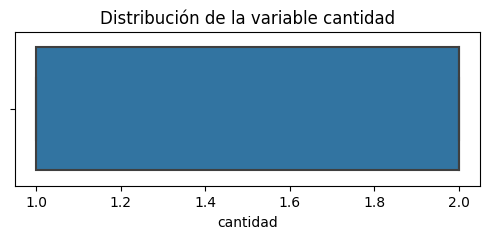

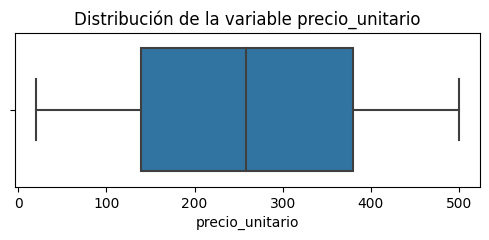

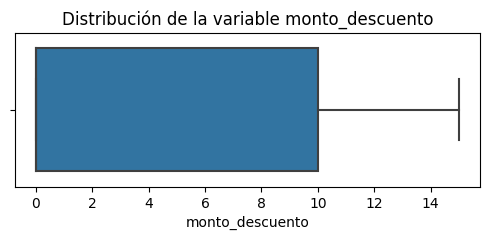

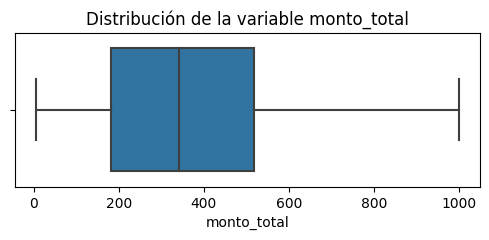


Descripción estadística de variables categóricas:

Descripción estadística de pais:
count      24600
unique         3
top       Mexico
freq        8305
Name: pais, dtype: object

Tabla de frecuencias pais:


,Frecuencia absoluta,Frecuencia relativa (%)
Mexico,8305,33.76
Colombia,8273,33.63
Argentina,8022,32.61



Descripción estadística de dispositivo:
count       24600
unique          2
top       desktop
freq        12524
Name: dispositivo, dtype: object

Tabla de frecuencias dispositivo:


,Frecuencia absoluta,Frecuencia relativa (%)
desktop,12524,50.91
mobile,12076,49.09



Descripción estadística de fuente_referencia:
count      24600
unique         3
top       social
freq        8268
Name: fuente_referencia, dtype: object

Tabla de frecuencias fuente_referencia:


,Frecuencia absoluta,Frecuencia relativa (%)
social,8268,33.61
organic,8190,33.29
paid_search,8142,33.10



Descripción estadística de nombre_producto:
count               24600
unique                  7
top       Jacket-Winter-M
freq                 4122
Name: nombre_producto, dtype: object

Tabla de frecuencias nombre_producto:


,Frecuencia absoluta,Frecuencia relativa (%)
Jacket-Winter-M,4122,16.76
Vacuum-Pro-Black,4114,16.72
Blender-XL-Red,4114,16.72
Sneakers-Urban-42,4072,16.55
Laptop-Gaming-16GB,2752,11.19
Tablet-Standard-64GB,2729,11.09
Phone-Pro-128GB,2697,10.96



Descripción estadística de categoria_producto:
count     24600
unique        3
top       Hogar
freq       8228
Name: categoria_producto, dtype: object

Tabla de frecuencias categoria_producto:


,Frecuencia absoluta,Frecuencia relativa (%)
Hogar,8228,33.45
Moda,8194,33.31
Electronica,8178,33.24


In [12]:
# Verificación de limpieza de datos

# Información general
print(f"\nInformación general:")
orders.info()

# Conteo de nulos
print(f"\nValores nulos: \n", orders.isna().sum())

# Conteo de duplicados por la clave primaria única "id_pedido"
print(f"\nDuplicados en id_pedido: ", orders["id_pedido"].duplicated().sum())

# Descripción estadística de variables numéricas
print(f"\nDescripción estadística de variables numéricas: ")
print(orders[orders_variables_numericas].describe())

# Boxplot de variables numéricas
print(f"\nBoxplot de variables numéricas: ")
for col in orders_variables_numericas:
    plt.figure(figsize = (6, 2))
    sns.boxplot(x=orders[col])
    plt.title(f'Distribución de la variable {col}')
    plt.show()

# Descripción destadística y conteos de variables categóricas
print(f"\nDescripción estadística de variables categóricas:")
for col in orders_variables_categoricas:
    print(f"\nDescripción estadística de {col}:")
    print(orders[col].describe())
    tabla_frecuencias = pd.DataFrame({
        "Frecuencia absoluta": orders[col].value_counts(),
        "Frecuencia relativa (%)": orders[col].value_counts(normalize=True).round(4)*100
    })
    print(f"\nTabla de frecuencias {col}:")
    display(tabla_frecuencias)

#### Revisión de **catalog**

In [13]:
# Validación general de datos y formatos
print(f"Información general:")
catalog.info()

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   nombre_producto     7 non-null      object 
 1   categoria_producto  7 non-null      object 
 2   costo_unitario      7 non-null      float64
 3   proveedor           7 non-null      object 
dtypes: float64(1), object(3)
memory usage: 352.0+ bytes


In [14]:
# Conteo de duplicados para el nombre_producto
print(f"Duplicados en nombre_producto: ", catalog["nombre_producto"].duplicated().sum())

Duplicados en nombre_producto:  0


In [15]:
# Variables numéricas para análisis

# Descripción estadística de variables numéricas
print(f"\nDescripción estadística costo_unitario: ")
print(catalog["costo_unitario"].describe())


Descripción estadística costo_unitario: 
count      7.000000
mean     102.252857
std      111.011563
min       10.120000
25%       16.905000
50%       25.210000
75%      182.975000
max      280.680000
Name: costo_unitario, dtype: float64


In [16]:
# Variables categóricas para análisis

catalog_variables_categoricas = ["nombre_producto", "categoria_producto", "proveedor"]

# Descripción destadística y conteos de variables categóricas
for col in catalog_variables_categoricas:
    print(f"\nDescripción estadística de {col}:")
    print(catalog[col].describe())
    tabla_frecuencias = pd.DataFrame({
    "Frecuencia absoluta": catalog[col].value_counts(),
    "Frecuencia relativa (%)": catalog[col].value_counts(normalize=True).round(4)*100
})
    print(f"\nTabla de frecuencias de {col}:")
    display(tabla_frecuencias)


Descripción estadística de nombre_producto:
count                      7
unique                     7
top       Laptop-Gaming-16GB
freq                       1
Name: nombre_producto, dtype: object

Tabla de frecuencias de nombre_producto:


,Frecuencia absoluta,Frecuencia relativa (%)
Laptop-Gaming-16GB,1,14.29
Jacket-Winter-M,1,14.29
Blender-XL-Red,1,14.29
Sneakers-Urban-42,1,14.29
Tablet-Standard-64GB,1,14.29
Phone-Pro-128GB,1,14.29
Vacuum-Pro-Black,1,14.29



Descripción estadística de categoria_producto:
count               7
unique              3
top       Electrónica
freq                3
Name: categoria_producto, dtype: object

Tabla de frecuencias de categoria_producto:


,Frecuencia absoluta,Frecuencia relativa (%)
Electrónica,3,42.86
Hogar,2,28.57
Moda,2,28.57



Descripción estadística de proveedor:
count                   7
unique                  7
top       Mcmillan-Rhodes
freq                    1
Name: proveedor, dtype: object

Tabla de frecuencias de proveedor:


,Frecuencia absoluta,Frecuencia relativa (%)
Mcmillan-Rhodes,1,14.29
Bowers LLC,1,14.29
Greene-Smith,1,14.29
"Rivera, Carr and Finley",1,14.29
Long-Reid,1,14.29
King Ltd,1,14.29
"Fuller, Pena and Myers",1,14.29


**Diagnóstico y tratamiento**:

* El dataset catalog no presentó inconsistencias con respecto a valores nulos.
* La variable `costo_unitario` tiene el formato correcto y no presenta valores imposibles negativos.
* La variable `nombre_producto` no se encuentra duplicada.
   - *Tratamiento*: se mantienen los datos en formato original

#### Revisión de **marketing**

In [17]:
# Validación general de datos y formatos
print(f"Información general:")
marketing.info()

Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   fecha       1620 non-null   object 
 1   pais        1620 non-null   object 
 2   id_campaña  1620 non-null   object 
 3   canal       1519 non-null   object 
 4   gasto       1620 non-null   float64
dtypes: float64(1), object(4)
memory usage: 63.4+ KB


In [18]:
# Conteo de valores nulos por columna
print(f"Valores nulos: \n", marketing.isna().sum())
filas_con_nulos = marketing.isna().any(axis=1).sum()

Valores nulos: 
 fecha           0
pais            0
id_campaña      0
canal         101
gasto           0
dtype: int64


In [19]:
# Variables numéricas para análisis

# Descripción estadística de variables numéricas
print(f"\nDescripción estadística gasto: ")
print(marketing["gasto"].describe())


Descripción estadística gasto: 
count    1620.00000
mean     1772.74292
std       734.43294
min       501.11000
25%      1128.03000
50%      1782.42500
75%      2420.68500
max      2999.36000
Name: gasto, dtype: float64


In [20]:
# Variables categóricas para análisis

marketing_variables_categoricas = ["pais", "id_campaña", "canal"]

# Descripción destadística y conteos de variables categóricas
for col in marketing_variables_categoricas:
    print(f"\nDescripción estadística de {col}:")
    print(marketing[col].describe())
    tabla_frecuencias = pd.DataFrame({
    "Frecuencia absoluta": marketing[col].value_counts(),
    "Frecuencia relativa (%)": marketing[col].value_counts(normalize=True).round(4)*100
})
    print(f"\nTabla de frecuencias de {col}:")
    display(tabla_frecuencias)


Descripción estadística de pais:
count         1620
unique           3
top       Colombia
freq           540
Name: pais, dtype: object

Tabla de frecuencias de pais:


,Frecuencia absoluta,Frecuencia relativa (%)
Colombia,540,33.33
Argentina,540,33.33
Mexico,540,33.33



Descripción estadística de id_campaña:
count                1620
unique                  9
top       social_Colombia
freq                  180
Name: id_campaña, dtype: object

Tabla de frecuencias de id_campaña:


,Frecuencia absoluta,Frecuencia relativa (%)
social_Colombia,180,11.11
organic_Argentina,180,11.11
organic_Mexico,180,11.11
organic_Colombia,180,11.11
paid_search_Mexico,180,11.11
social_Mexico,180,11.11
paid_search_Argentina,180,11.11
social_Argentina,180,11.11
paid_search_Colombia,180,11.11



Descripción estadística de canal:
count            1519
unique              3
top       paid_search
freq              507
Name: canal, dtype: object

Tabla de frecuencias de canal:


,Frecuencia absoluta,Frecuencia relativa (%)
paid_search,507,33.38
organic,506,33.31
social,506,33.31


In [21]:
# Análisis de valores nulos en "canal", y posibles coincidencias con "id_campaña"

# Extraer canal desde el id_camapaña
canal_en_id_campaña = marketing["id_campaña"].str.rsplit("_", n=1).str[0]

# Comparar canal registrado vs. canal utilizado en campaña
diagnostico = pd.crosstab(
    marketing["canal"].fillna("Nulo"),
    canal_en_id_campaña
)

# Tabla obtenida
diagnostico

id_campaña,organic,paid_search,social
canal,,,
Nulo,34,33,34
organic,506,0,0
paid_search,0,507,0
social,0,0,506


**Diagnóstico y tratamiento**:

* La variable `fecha` está en formato `object`.
   - *Tratamiento*: se convierte a formato fecha.
* La variable `gasto` está formateada correctamente a `float64` y no presenta valores imposibles negativos.
   - *Tratamiento*: se mantienen sus valores originales.
* La variable `canal` presenta 101 valores nulos.
   - *Tratamiento*: se realizará una imputación de este valor, apoyándonos en que hay coincidencia exacta entre la variable `id_campaña` con las variables `canal` y `pais`.  `id_campaña` siempre se presenta como "*`canal`*_*`pais`*".

In [22]:
# Limpieza de datos

# Formato de fecha
marketing["fecha"] = pd.to_datetime(marketing["fecha"], errors="coerce")

# Imputación de valores de id_campaña a canal
marketing["canal"] = marketing["canal"].fillna(marketing["id_campaña"].str.rsplit("_", n=1).str[0])

In [23]:
# Verificación de limpieza de datos

# Información general
print(f"\nInformación general:")
marketing.info()

# Conteo de nulos
print(f"\nValores nulos: \n", marketing.isna().sum())

# Descripción destadística y conteos de variables categóricas
for col in marketing_variables_categoricas:
    print(f"\nDescripción estadística de {col}:")
    print(marketing[col].describe())
    tabla_frecuencias = pd.DataFrame({
    "Frecuencia absoluta": marketing[col].value_counts(),
    "Frecuencia relativa (%)": marketing[col].value_counts(normalize=True).round(4)*100
})
    print(f"\nTabla de frecuencias de {col}:")
    display(tabla_frecuencias)


Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   fecha       1620 non-null   datetime64[ns]
 1   pais        1620 non-null   object        
 2   id_campaña  1620 non-null   object        
 3   canal       1620 non-null   object        
 4   gasto       1620 non-null   float64       
dtypes: datetime64[ns](1), float64(1), object(3)
memory usage: 63.4+ KB

Valores nulos: 
 fecha         0
pais          0
id_campaña    0
canal         0
gasto         0
dtype: int64

Descripción estadística de pais:
count         1620
unique           3
top       Colombia
freq           540
Name: pais, dtype: object

Tabla de frecuencias de pais:


,Frecuencia absoluta,Frecuencia relativa (%)
Colombia,540,33.33
Argentina,540,33.33
Mexico,540,33.33



Descripción estadística de id_campaña:
count                1620
unique                  9
top       social_Colombia
freq                  180
Name: id_campaña, dtype: object

Tabla de frecuencias de id_campaña:


,Frecuencia absoluta,Frecuencia relativa (%)
social_Colombia,180,11.11
organic_Argentina,180,11.11
organic_Mexico,180,11.11
organic_Colombia,180,11.11
paid_search_Mexico,180,11.11
social_Mexico,180,11.11
paid_search_Argentina,180,11.11
social_Argentina,180,11.11
paid_search_Colombia,180,11.11



Descripción estadística de canal:
count        1620
unique          3
top       organic
freq          540
Name: canal, dtype: object

Tabla de frecuencias de canal:


,Frecuencia absoluta,Frecuencia relativa (%)
organic,540,33.33
paid_search,540,33.33
social,540,33.33


---

**Exportación**: Una vez finalizada la limpieza, se exportan los datasets procesados para utilizarlos en las etapas posteriores del análisis.

In [24]:
# Exportar datasets
orders.to_csv('orders_clean.csv', index=False)
catalog.to_csv('catalog_clean.csv', index=False)
marketing.to_csv('marketing_clean.csv', index=False)

---

## Rentabilidad y desempeño comercial

### Evaluación de rentabilidad y desempeño comercial

Para evaluar el desempeño comercial, se integran los datos de pedidos, catálogo y marketing.

#### Rentabilidad del negocio

In [25]:
# Creación de una tabla conjunta para cálculo de rentabilidad
orders_con_costos = orders.merge(
    catalog[["nombre_producto", "costo_unitario"]],
    on="nombre_producto",
    how="left"
)

# Creación de la columna "costo_total"
orders_con_costos["costo_total"] = orders_con_costos["cantidad"] * orders_con_costos["costo_unitario"]

# Verificación
orders_con_costos.head(5)

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total,costo_unitario,costo_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37,189.31,378.62
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86,25.21,25.21
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99,176.64,353.28
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87,25.21,25.21
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28,176.64,176.64


In [26]:
# Ingreso total
ingreso_total = orders_con_costos["monto_total"].sum().round(2)
print(f"Ingreso total: {ingreso_total:,} UM")

# Costo total
costo_total = orders_con_costos["costo_total"].sum().round(2)
print(f"\nCosto total: {costo_total:,} UM")

# Inversión en marketing
gasto_marketing = marketing["gasto"].sum().round(2)
print(f"\nInversión total en marketing: {gasto_marketing:,} UM")

## Rentabilidad del negocio
# Ganancia Bruta
ganancia_bruta = (ingreso_total - costo_total).round(2)
print(f"\nGanancia Bruta: {ganancia_bruta:,} UM.")

# Ganancia Neta
ganancia_neta = (ingreso_total - costo_total - gasto_marketing).round(2)
print(f"\nGanancia Neta: {ganancia_neta:,} UM.")

# Rentabilidad 
rentabilidad = ganancia_neta / (costo_total)
print(f"\nRentabilidad: {rentabilidad:.2%}")

# Rentabilidad después de inversión en Marketing
rentabilidad_considerando_marketing = ganancia_neta / (costo_total + gasto_marketing)
print(f"\nRentabilidad después de inversión en Marketing: {rentabilidad_considerando_marketing:.2%}")

Ingreso total: 9,495,909.61 UM

Costo total: 3,787,408.32 UM

Inversión total en marketing: 2,871,843.53 UM

Ganancia Bruta: 5,708,501.29 UM.

Ganancia Neta: 2,836,657.76 UM.

Rentabilidad: 74.90%

Rentabilidad después de inversión en Marketing: 42.60%


**Conclusión**:

RappiPlus presenta un desempeño rentable durante el periodo analizado. Los ingresos alcanzan **9.50 M UM**, frente a **3.79 M UM** en costos de productos y **2.87 M UM** de inversión en marketing.

Después de considerar ambos costos, la **ganancia neta asciende a 2.84 M UM**, con una rentabilidad de **42.60%** sobre los costos totales e inversión en marketing.

Estos resultados muestran una operación rentable, aunque el gasto en marketing representa un componente relevante al evaluar la rentabilidad final del negocio.

#### Comportamiento de ventas

In [27]:
# Ticket promedio por orden
ticket_promedio = orders_con_costos["monto_total"].mean().round(2)
print(f"Ticket promedio por orden: {ticket_promedio:,} UM.")

# Cantidad vendida promedio por orden
cantidad_promedio = orders_con_costos["cantidad"].mean().round(1)
print(f"\nCantidfad promedio por orden: {cantidad_promedio:.2f} unidades.")

# Producto más vendido
ranking_productos = (
    orders_con_costos
        .groupby("nombre_producto")["cantidad"]
        .sum()
        .sort_values(ascending=False)
)
print(f"\nEl producto con las mayores ventas:")
print(ranking_productos.head(1))


# Gastos en marketing por canal
gasto_por_canales_marketing = (
    marketing
    .groupby("canal")["gasto"]
    .sum()
    .sort_values(ascending=False)
)
print(f"Tabla de gasto de marketing por canal:")
print(gasto_por_canales_marketing)

Ticket promedio por orden: 386.01 UM.

Cantidfad promedio por orden: 1.50 unidades.

El producto con las mayores ventas:
nombre_producto
Vacuum-Pro-Black    6203.0
Name: cantidad, dtype: float64
Tabla de gasto de marketing por canal:
canal
social         976818.37
organic        972650.96
paid_search    922374.20
Name: gasto, dtype: float64


**Conclusión**:

El comportamiento de ventas muestra un ticket promedio de **386.01 UM** y un promedio de **1.50 unidades por orden**, lo que refleja pedidos de bajo volumen por transacción.

El **Vacuum-Pro-Black** lidera las ventas con **6,203 unidades**, posicionándose como el producto con mayor volumen comercial.

En marketing, los canales **social** y **organic** concentran la mayor inversión, con **976,818.37 UM** y **972,650.96 UM**, respectivamente, mientras que **paid_search** registra **922,374.20 UM**.

---

## Funnel de conversión

El siguiente análisis examina el recorrido de los usuarios dentro de la plataforma para identificar en qué etapas se concentra la pérdida de usuarios y cuál es la conversión final del proceso.

⚙️ **Conexión a la base de datos:**  
Se utiliza una conexión a la base de datos para consultar la tabla **events** mediante SQL.

In [28]:
import pandas as pd
from sqlalchemy import create_engine

# ======================
# Conexión
# ======================
db_config = {
    'user': '<DB_USER>',
    'pwd': '<DB_PASSWORD>',
    'host': '<DB_HOST>',
    'port': 5432,
    'db': '<DB_NAME>'
}

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db']
)

engine = create_engine(
    connection_string,
    connect_args={'sslmode': 'require'}
)

### Construcción del funnel

Se contabilizan los usuarios únicos que alcanzan cada evento y se ordenan las etapas de acuerdo con el flujo esperado del usuario.

In [29]:
# Explorar tabla events
# =========================
query_events = '''
SELECT *
FROM events;
'''
events = pd.read_sql(query_events, con=engine)
events.head()

,id_usuario,id_sesion,nombre_evento,timestamp_evento,pais,dispositivo,fuente_referencia,categoria_producto
0,user_6772,6a97f2af-32ae-4186-8c92-04025be1a27b,first_visit,2025-05-17,Colombia,desktop,organic,Moda
1,user_5883,369b767c-1c33-4b2f-a652-c7c0ef92cfc9,add_to_cart,2025-02-23,Mexico,mobile,social,Hogar
2,user_5946,60039041-e78b-474c-87b3-c0b7e9c30708,add_payment_info,2025-05-15,Colombia,desktop,social,Electronica
3,user_827,18252a64-f389-4ef7-9e58-dadad4a3491e,purchase,2025-03-31,Mexico,mobile,social,Moda
4,user_2361,221b364e-cdc5-4668-b698-18d5ba849a67,first_visit,2025-01-22,Argentina,desktop,paid_search,Electronica


In [30]:
# Explorar rango de fechas
# =========================
query_fechas = '''
SELECT
    MIN(timestamp_evento) AS fecha_minima,
    MAX(timestamp_evento) AS fecha_maxima
FROM events;
'''
events = pd.read_sql(query_fechas, con=engine)
events.head()

,fecha_minima,fecha_maxima
0,2025-01-01,2025-06-30


In [31]:
# Análisis de usuarios únicos, usando como base a aquellos que tuvieron su primera visita en el rango de fechas del dataset
# ======================

query_totals = '''
WITH first_visit AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'first_visit'
    AND timestamp_evento BETWEEN '2025-01-01' AND '2025-06-30'
),
select_item AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'select_item'
    AND timestamp_evento BETWEEN '2025-01-01' AND '2025-06-30'
),
add_to_cart AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'add_to_cart'
    AND timestamp_evento BETWEEN '2025-01-01' AND '2025-06-30'
),
begin_checkout AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'begin_checkout'
    AND timestamp_evento BETWEEN '2025-01-01' AND '2025-06-30'
),
add_payment_info AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'add_payment_info'
    AND timestamp_evento BETWEEN '2025-01-01' AND '2025-06-30'
),

purchase AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'purchase'
    AND timestamp_evento BETWEEN '2025-01-01' AND '2025-06-30'
)

SELECT 
    COUNT(fv.id_usuario) AS usuarios_first_visit,
    COUNT(si.id_usuario) AS usuarios_select_item,
    COUNT(atc.id_usuario) AS usuarios_add_to_cart,
    COUNT(bc.id_usuario) AS usuarios_begin_checkout,
    COUNT(api.id_usuario) AS usuarios_add_payment_info,
    COUNT(p.id_usuario) AS usuarios_purchase

FROM first_visit AS fv

LEFT JOIN select_item AS si
    ON fv.id_usuario = si.id_usuario

LEFT JOIN add_to_cart AS atc
    ON fv.id_usuario = atc.id_usuario

LEFT JOIN begin_checkout AS bc
    ON fv.id_usuario = bc.id_usuario

LEFT JOIN add_payment_info AS api
    ON fv.id_usuario = api.id_usuario

LEFT JOIN purchase AS p
    ON fv.id_usuario = p.id_usuario;
'''
totals = pd.read_sql(query_totals, con=engine)
totals

,usuarios_first_visit,usuarios_select_item,usuarios_add_to_cart,usuarios_begin_checkout,usuarios_add_payment_info,usuarios_purchase
0,7796,7393,7439,7031,6088,6068


In [32]:
# Explorar usuarios que pasan a etapas sin registros en etapas anteriores
# =========================

query_usuarios_sin_registro_en_etapa_anterior = '''
WITH first_visit AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'first_visit'
),
select_item AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'select_item'
),
add_to_cart AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'add_to_cart'
),
begin_checkout AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'begin_checkout'
),
add_payment_info AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'add_payment_info'
),
purchase AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'purchase'
)

SELECT

    -- Usuarios que llegan a select_item sin first_visit
    (SELECT COUNT(*)
     FROM select_item AS si
     WHERE si.id_usuario NOT IN (
         SELECT id_usuario FROM first_visit
     )
    ) AS select_item_sin_first_visit,

    -- Usuarios que llegan a add_to_cart sin select_item
    (SELECT COUNT(*)
     FROM add_to_cart AS atc
     WHERE atc.id_usuario NOT IN (
         SELECT id_usuario FROM select_item
     )
    ) AS add_to_cart_sin_select_item,

    -- Usuarios que llegan a begin_checkout sin add_to_cart
    (SELECT COUNT(*)
     FROM begin_checkout AS bc
     WHERE bc.id_usuario NOT IN (
         SELECT id_usuario FROM add_to_cart
     )
    ) AS begin_checkout_sin_add_to_cart,

    -- Usuarios que llegan a add_payment_info sin begin_checkout
    (SELECT COUNT(*)
     FROM add_payment_info AS api
     WHERE api.id_usuario NOT IN (
         SELECT id_usuario FROM begin_checkout
     )
    ) AS add_payment_info_sin_begin_checkout,

    -- Usuarios que llegan a purchase sin add_payment_info
    (SELECT COUNT(*)
     FROM purchase AS p
     WHERE p.id_usuario NOT IN (
         SELECT id_usuario FROM add_payment_info
     )
    ) AS purchase_sin_add_payment_info;

'''
nombres_evento = pd.read_sql(query_usuarios_sin_registro_en_etapa_anterior, con=engine)
nombres_evento.head()

,select_item_sin_first_visit,add_to_cart_sin_select_item,begin_checkout_sin_add_to_cart,add_payment_info_sin_begin_checkout,purchase_sin_add_payment_info
0,189,401,321,612,1382


**Hallazgos y Limitaciones**:
* Se identificó que existen usuarios que llegan a etapas posteriores del funnel sin que exista el registro de eventos anteriores. Esto sugiere la presencia de posibles rutas alternativas o eventos no registrados dentro del período analizado. De esta forma, los resultados deben interpretarse como usuarios que realizaron cada evento dentro de la cohorte, y no necesariamente como una secuencia obligatoria de pasos.
* Para analizar estrictamente los usuarios que realizaron un avance secuencial en el funnel, se tomará como referencia para la unión (JOIN) a los usuarios que aparezcan en el paso inmediato anterior. 

In [33]:
# Totales del funnel. Funnel secuencial por presencia de eventos 
# =========================

query_secuencial_por_presencia_de_eventos = '''
WITH first_visit AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'first_visit'
      AND timestamp_evento BETWEEN '2025-01-01' AND '2025-06-30'
),
select_item AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'select_item'
      AND timestamp_evento BETWEEN '2025-01-01' AND '2025-06-30'
),
add_to_cart AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'add_to_cart'
      AND timestamp_evento BETWEEN '2025-01-01' AND '2025-06-30'
),
begin_checkout AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'begin_checkout'
      AND timestamp_evento BETWEEN '2025-01-01' AND '2025-06-30'
),
add_payment_info AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'add_payment_info'
      AND timestamp_evento BETWEEN '2025-01-01' AND '2025-06-30'
),
purchase AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'purchase'
      AND timestamp_evento BETWEEN '2025-01-01' AND '2025-06-30'
)

SELECT
    COUNT(DISTINCT fv.id_usuario) AS usuarios_first_visit,
    COUNT(DISTINCT si.id_usuario) AS usuarios_select_item,
    COUNT(DISTINCT atc.id_usuario) AS usuarios_add_to_cart,
    COUNT(DISTINCT bc.id_usuario) AS usuarios_begin_checkout,
    COUNT(DISTINCT api.id_usuario) AS usuarios_add_payment_info,
    COUNT(DISTINCT p.id_usuario) AS usuarios_purchase

FROM first_visit AS fv
LEFT JOIN select_item AS si
    ON fv.id_usuario = si.id_usuario
LEFT JOIN add_to_cart AS atc
    ON si.id_usuario = atc.id_usuario
LEFT JOIN begin_checkout AS bc
    ON atc.id_usuario = bc.id_usuario
LEFT JOIN add_payment_info AS api
    ON bc.id_usuario = api.id_usuario
LEFT JOIN purchase AS p
    ON api.id_usuario = p.id_usuario;

'''
nombres_evento = pd.read_sql(query_secuencial_por_presencia_de_eventos, con=engine)
nombres_evento.head()

,usuarios_first_visit,usuarios_select_item,usuarios_add_to_cart,usuarios_begin_checkout,usuarios_add_payment_info,usuarios_purchase
0,7796,7393,7052,6364,4967,3857


**Conclusión**:

El funnel principal, contando solo usuarios que hayan realizado los pasos anteriores, muestra una disminución progresiva desde 7,796 usuarios en first_visit hasta 3,857 en purchase. El mayor drop-off ocurre entre begin_checkout y add_payment_info, donde se pierden 1,397 usuarios, convirtiéndose en el principal punto de abandono del funnel.

### Análisis de conversión

A partir del número de usuarios en cada etapa, se calcula la tasa de conversión entre pasos y se identifica dónde ocurre la mayor pérdida de usuarios.

In [34]:
# Conversiones tomando como referencia el total de usuarios (first_visit)
# ======================

query_conversion = '''
WITH first_visit AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'first_visit'
    AND timestamp_evento BETWEEN '2025-01-01' AND '2025-06-30'
),
select_item AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'select_item'
    AND timestamp_evento BETWEEN '2025-01-01' AND '2025-06-30'
),
add_to_cart AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'add_to_cart'
    AND timestamp_evento BETWEEN '2025-01-01' AND '2025-06-30'
),
begin_checkout AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'begin_checkout'
    AND timestamp_evento BETWEEN '2025-01-01' AND '2025-06-30'
),
add_payment_info AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'add_payment_info'
    AND timestamp_evento BETWEEN '2025-01-01' AND '2025-06-30'
),
purchase AS (
    SELECT DISTINCT id_usuario
    FROM events
    WHERE nombre_evento = 'purchase'
    AND timestamp_evento BETWEEN '2025-01-01' AND '2025-06-30'
),
funnel_counts AS (
    SELECT
        COUNT(fv.id_usuario) AS usuarios_first_visit,
        COUNT(si.id_usuario) AS usuarios_select_item,
        COUNT(atc.id_usuario) AS usuarios_add_to_cart,
        COUNT(bc.id_usuario) AS usuarios_begin_checkout,
        COUNT(api.id_usuario) AS usuarios_add_payment_info,
        COUNT(p.id_usuario) AS usuarios_purchase

    FROM first_visit AS fv
    LEFT JOIN select_item AS si
        ON fv.id_usuario = si.id_usuario
    LEFT JOIN add_to_cart AS atc
        ON si.id_usuario = atc.id_usuario
    LEFT JOIN begin_checkout AS bc
        ON atc.id_usuario = bc.id_usuario
    LEFT JOIN add_payment_info AS api
        ON bc.id_usuario = api.id_usuario
    LEFT JOIN purchase AS p
        ON api.id_usuario = p.id_usuario
)

SELECT

    -- Conversión acumulada respecto a first_visit
    ROUND(usuarios_select_item * 100.0 /
          NULLIF(usuarios_first_visit, 0), 2) AS conversion_select_item,

    ROUND(usuarios_add_to_cart * 100.0 /
          NULLIF(usuarios_first_visit, 0), 2) AS conversion_add_to_cart,

    ROUND(usuarios_begin_checkout * 100.0 /
          NULLIF(usuarios_first_visit, 0), 2) AS conversion_begin_checkout,

    ROUND(usuarios_add_payment_info * 100.0 /
          NULLIF(usuarios_first_visit, 0), 2) AS conversion_add_payment_info,

    ROUND(usuarios_purchase * 100.0 /
          NULLIF(usuarios_first_visit, 0), 2) AS conversion_purchase,

    -- Drop-off entre etapas

    ROUND((usuarios_first_visit - usuarios_select_item) * 100.0 / NULLIF(usuarios_first_visit, 0), 2) AS dropoff_first_visit_pct,
    
    ROUND((usuarios_select_item - usuarios_add_to_cart) * 100.0 / NULLIF(usuarios_select_item, 0), 2) AS dropoff_select_item_pct,
    
    ROUND((usuarios_add_to_cart - usuarios_begin_checkout) * 100.0 / NULLIF(usuarios_add_to_cart, 0), 2) AS dropoff_add_to_cart_pct,
    
    ROUND((usuarios_begin_checkout - usuarios_add_payment_info) * 100.0 / NULLIF(usuarios_begin_checkout, 0), 2) AS dropoff_begin_checkout_pct,
    
    ROUND((usuarios_add_payment_info - usuarios_purchase) * 100.0 / NULLIF(usuarios_add_payment_info, 0), 2) AS dropoff_add_payment_info_pct

FROM funnel_counts;
'''

conversion = pd.read_sql(query_conversion, con=engine)
conversion

,conversion_select_item,conversion_add_to_cart,conversion_begin_checkout,conversion_add_payment_info,conversion_purchase,dropoff_first_visit_pct,dropoff_select_item_pct,dropoff_add_to_cart_pct,dropoff_begin_checkout_pct,dropoff_add_payment_info_pct
0,94.83,90.46,81.63,63.71,49.47,5.17,4.61,9.76,21.95,22.35


**Conclusión**:

El funnel alcanza una conversión acumulada de 49.47% desde `first_visit` hasta `purchase`.

La mayor pérdida relativa ocurre entre `add_payment_info` y `purchase`, con un **22.35% de abandono**. En cambio, la mayor pérdida absoluta ocurre entre `begin_checkout` y `add_payment_info`, con **1,397 usuarios**.

En conjunto, las etapas finales del proceso de compra concentran las principales oportunidades de mejora en conversión.

---

## Retención de usuarios por cohortes

El análisis de cohortes permite evaluar la capacidad de RappiPlus para mantener activos a los usuarios después de su registro y detectar cómo evoluciona la retención durante las primeras semanas.

**Tablas utilizadas:**
- `users`
- `user_activity`

### Construcción de las cohortes

Se identifica la cohorte de cada usuario según su **mes de registro** y se calcula la actividad durante las semanas posteriores al registro.

Para cada cohorte se determina:
- Usuarios activos en la semana 1 (`retenido_w1`)
- Usuarios activos en la semana 2 (`retenido_w2`)
- Usuarios activos en la semana 3 (`retenido_w3`)
- Usuarios activos en la semana 4 (`retenido_w4`)

A partir de estos valores se calcula el porcentaje de retención semanal respecto al número inicial de usuarios de cada cohorte.

La fecha de registro se convierte al formato `DATE` mediante `CAST(fecha_registro AS DATE)` para facilitar la construcción de las cohortes.

In [35]:
# Explorar tabla users
# =========================
query_users = '''
SELECT *
FROM users;
'''
users = pd.read_sql(query_users, con=engine)
users.head(5)

,id_usuario,fecha_registro,país,dispositivo,tipo_plan
0,user_0,2025-01-29,Mexico,mobile,free
1,user_1,2025-01-07,Mexico,mobile,free
2,user_2,2025-03-12,Argentina,mobile,free
3,user_3,2025-03-04,Mexico,desktop,free
4,user_4,2025-02-27,Argentina,desktop,free


In [36]:
# Explorar tabla user_activity
# =========================
query_user_activity = '''
SELECT *
FROM user_activity;
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(5)

,id_usuario,fecha_actividad,dias_despues_registro,activo
0,user_0,2025-02-05,7,0
1,user_0,2025-02-12,14,1
2,user_0,2025-02-19,21,1
3,user_0,2025-02-26,28,0
4,user_1,2025-01-14,7,0


In [37]:
# Retención por cohortes
# ======================

query_cohort_retention_final = '''

WITH cohortes AS (
    SELECT
        TO_CHAR(DATE_TRUNC('month', CAST(fecha_registro AS DATE)), 'YYYY-MM') AS cohorte,
        COUNT(DISTINCT id_usuario) AS usuarios_cohorte
    FROM users 
    GROUP BY 
        cohorte
),
actividad AS (
    SELECT 
        TO_CHAR(DATE_TRUNC('month', CAST(u.fecha_registro AS DATE)), 'YYYY-MM') AS cohorte,
        COUNT (DISTINCT CASE WHEN ua.dias_despues_registro >= 7 AND ua.activo = 1 THEN ua.id_usuario END) AS retenido_w1,
        COUNT (DISTINCT CASE WHEN ua.dias_despues_registro >= 14 AND ua.activo = 1 THEN ua.id_usuario END) AS retenido_w2,
        COUNT (DISTINCT CASE WHEN ua.dias_despues_registro >= 21 AND ua.activo = 1 THEN ua.id_usuario END) AS retenido_w3,
        COUNT (DISTINCT CASE WHEN ua.dias_despues_registro >= 28 AND ua.activo = 1 THEN ua.id_usuario END) AS retenido_w4
    FROM users AS u
    LEFT JOIN user_activity AS ua
        ON u.id_usuario = ua.id_usuario
    GROUP BY
        cohorte
)

SELECT 
    c.cohorte,
    c.usuarios_cohorte as total_usuarios,
    a.retenido_w1,
    a.retenido_w2,
    a.retenido_w3,
    a.retenido_w4,
    ROUND(retenido_w1 * 100.0 / NULLIF(c.usuarios_cohorte,0),1) AS semana_1,
    ROUND(retenido_w2 * 100.0 / NULLIF(c.usuarios_cohorte,0),1) AS semana_2,
    ROUND(retenido_w3 * 100.0 / NULLIF(c.usuarios_cohorte,0),1) AS semana_3,
    ROUND(retenido_w4 * 100.0 / NULLIF(c.usuarios_cohorte,0),1) AS semana_4

FROM cohortes AS c
LEFT JOIN actividad AS a
    ON c.cohorte = a.cohorte

;
'''

cohorte_final = pd.read_sql(query_cohort_retention_final, con=engine)
cohorte_final

,cohorte,total_usuarios,retenido_w1,retenido_w2,retenido_w3,retenido_w4,semana_1,semana_2,semana_3,semana_4
0,2025-01,1627,1381,1253,1027,671,84.9,77.0,63.1,41.2
1,2025-02,1444,1255,1154,940,575,86.9,79.9,65.1,39.8
2,2025-03,1636,1428,1306,1060,673,87.3,79.8,64.8,41.1
3,2025-04,1606,1394,1261,1022,652,86.8,78.5,63.6,40.6
4,2025-05,1687,1446,1321,1088,679,85.7,78.3,64.5,40.2


**Conclusión**:

La retención disminuye de forma consistente conforme aumenta el tiempo desde el registro. En las distintas cohortes, pasa de aproximadamente **85–87% en la semana 1** a **40–41% en la semana 4**.

La cohorte de **enero y marzo** presenta los mejores niveles de retención durante las primeras cuatro semanas, mientras que **febrero** muestra los resultados más bajos hacia la semana 4.

En términos generales, RappiPlus conserva cerca del **40% de los usuarios después del primer mes**, lo que implica una pérdida aproximada del **60% de la base inicial** durante este periodo.

---

## Experimento A/B: impacto en la conversión

El experimento evalúa si una modificación en la interfaz del checkout genera un cambio estadísticamente significativo en la **tasa de conversión de compra**.

Para este análisis, se empleará el dataset `experimento`, cuya métrica `conversion` toma el valor **1** cuando el usuario completa la compra y **0** cuando no lo hace.

El análisis comprende tres etapas:

1. **Planteamiento de hipótesis estadísticas**
2. **Aplicación del test estadístico**
3. **Interpretación de los resultados y evaluación del impacto del cambio**

In [38]:
# Importar librerías
import pandas as pd
from statsmodels.stats.proportion import proportions_ztest

In [39]:
# Cargar archivo
experimento = pd.read_csv("https://practicum-content.s3.amazonaws.com/datasets/experiment_checkout_ui.csv")

In [40]:
# Vista previa
experimento.head()

,id_usuario,variante,convirtio,dispositivo,pais,duracion_sesion,timestamp
0,exp_user_0,tratamiento,0,mobile,Argentina,114.41,2025-03-28
1,exp_user_1,tratamiento,0,desktop,Mexico,170.03,2025-01-15
2,exp_user_2,control,1,mobile,Colombia,140.21,2025-03-18
3,exp_user_3,tratamiento,0,mobile,Colombia,151.45,2025-06-03
4,exp_user_4,tratamiento,0,desktop,Mexico,299.96,2025-01-12


In [41]:
# Exploración inicial del dataset

print(f"\nInformación del dataset:")
experimento.info()

print(f"\nValores Nulos:\n{experimento.isna().sum()}")

print(f"\nValores duplicados: {experimento.duplicated().sum()}")

print(f"\nDistribución de variantes:\n{experimento['variante'].value_counts()}")

print(f"\nConversión por variante:")
conversion = (
    experimento
    .groupby("variante")["convirtio"]
    .agg(["count", "sum", "mean"])
    .reset_index())
conversion["conversion_pct"] = (conversion["mean"] * 100).round(2)
conversion


Información del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_usuario       10000 non-null  object 
 1   variante         10000 non-null  object 
 2   convirtio        10000 non-null  int64  
 3   dispositivo      10000 non-null  object 
 4   pais             10000 non-null  object 
 5   duracion_sesion  10000 non-null  float64
 6   timestamp        10000 non-null  object 
dtypes: float64(1), int64(1), object(5)
memory usage: 547.0+ KB

Valores Nulos:
id_usuario         0
variante           0
convirtio          0
dispositivo        0
pais               0
duracion_sesion    0
timestamp          0
dtype: int64

Valores duplicados: 0

Distribución de variantes:
tratamiento    5035
control        4965
Name: variante, dtype: int64

Conversión por variante:


,variante,count,sum,mean,conversion_pct
0,control,4965,779,0.156898,15.69
1,tratamiento,5035,820,0.162860,16.29


Hipótesis y método estadístico
   - **H₀ (Hipótesis nula):** la tasa de conversión es igual entre control y tratamiento. Cualquier diferencia se debe al azar del muestreo.
   - **H₁ (Hipótesis alternativa):** la tasa de conversión es diferente entre ambos grupos. Hay un factor que influye en la decisión de compra.

**Test estadístico:** Prueba z de proporciones

**Nivel de significancia alpha:** 0.05

In [42]:
# Preparación de datos para el test

# Conversiones por tratamiento
conversiones = experimento.groupby("variante")["convirtio"].sum()
# Total de usuarios por tratamiento
totales = experimento.groupby("variante")["convirtio"].count()

# Conversiones por tratamiento en formato lista
conversiones_list = [conversiones["control"], conversiones["tratamiento"]]
# Total de usuarios por tratamiento en formato lista
totales_list = [totales["control"], totales["tratamiento"]]

In [43]:
print("\nConversiones por tratamiento: ")
print(conversiones)
print("\nTotal de usuarios por tratamiento: ")
print(totales)
print("\nConversiones por tratamiento (lista): ")
print(conversiones_list)
print("\nTotal de usuarios por tratamiento (lista): ")
print(totales_list)


Conversiones por tratamiento: 
variante
control        779
tratamiento    820
Name: convirtio, dtype: int64

Total de usuarios por tratamiento: 
variante
control        4965
tratamiento    5035
Name: convirtio, dtype: int64

Conversiones por tratamiento (lista): 
[779, 820]

Total de usuarios por tratamiento (lista): 
[4965, 5035]


In [44]:
# Aplicar prueba y visualizar resultados
z_stat, p_value = proportions_ztest(conversiones_list , totales_list)
print(f"Estadístico z: {z_stat}")
print(f"Valor p: {p_value}")

Estadístico z: -0.8132782986429474
Valor p: 0.41605851639119995


**Interpretación de resultados**:

La tasa de conversión fue de **15.69%** en el grupo control y **16.29%** en el grupo tratamiento, una diferencia de **0.60 puntos porcentuales**.

Sin embargo, la prueba Z de proporciones obtuvo un **p-value de 0.416**, superior al nivel de significancia de **0.05**. Por lo tanto, **no se rechaza la hipótesis nula** y no existe evidencia estadísticamente significativa de que el cambio en la interfaz haya generado un impacto en la conversión.

**Recomendaciones**:

No se recomienda implementar el cambio como una mejora comprobada de conversión, ya que el experimento no demuestra un efecto estadísticamente significativo.

Como siguiente paso, se pueden realizar nuevas pruebas para identificar oportunidades de mejora en el checkout.

---

## Dashboard de desempeño en Power BI

El análisis se consolida en un dashboard interactivo desarrollado en **Power BI**, diseñado para transformar los resultados del análisis en una herramienta de consulta y seguimiento del desempeño comercial.

El dashboard integra información de **ventas, costos, marketing y rentabilidad**, permitiendo explorar los resultados desde una vista ejecutiva hasta el detalle de productos y órdenes.

### Overview ejecutivo

La vista principal presenta los principales indicadores de desempeño:

- Revenue total
- Profit total
- Gasto total en marketing
- Ticket promedio
- Cantidad promedio de productos por orden

También permite analizar la evolución y distribución del desempeño comercial mediante visualizaciones y filtros interactivos.

### Detalle y exploración

La segunda vista permite profundizar en el desempeño de los productos y órdenes, incluyendo:

- Revenue, costos, profit y cantidad vendida
- Desempeño por producto y categoría
- Filtros para explorar los datos
- Drill-through desde el producto hasta sus órdenes relacionadas

El dashboard funciona como la capa final del análisis, conectando los hallazgos obtenidos mediante Python y SQL con una herramienta orientada a la exploración y toma de decisiones.